# 06 — Kepler Model Complexity Analysis



In [ ]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    accuracy_score, roc_auc_score
)
from sklearn.exceptions import ConvergenceWarning
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=ConvergenceWarning)


DATA_DIR = Path("Kepler_Datasets")

X = pd.read_csv(DATA_DIR / "X_train.csv")
y = pd.read_csv(DATA_DIR / "y_train.csv")["target"].astype(int).to_numpy()
groups = pd.read_csv(DATA_DIR / "train_ids.csv")["kepid"].to_numpy()


assert len(X) == len(y) == len(groups)
assert X.shape[1] == 19

print(
    f"Training observations: {len(X):,}; "
    f"features: {X.shape[1]}; "
    f"unique stars: {len(np.unique(groups)):,}"
)

Training observations: 7,662; features: 19; unique stars: 6,571


## Models and complexity measures

- **Decision Tree:** maximum depth 8, balanced class weights, at least 10 samples per leaf.
- **MLP:** hidden layers 64–32, ReLU/Adam, L2 alpha 0.01, up to 90 iterations.
- **XGBoost:** 600 boosting trees, depth 8, learning rate 0.05, L2 lambda 1, `min_child_weight=5`, row and feature subsampling 0.8, no extra positive-class weight. Missing values are handled natively by XGBoost.


In [2]:
def make_model(name):
    if name == "Tuned Decision Tree":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("tree", DecisionTreeClassifier(
                max_depth=8, min_samples_split=10, min_samples_leaf=10,
                class_weight="balanced", random_state=42
            ))
        ])
    if name == "Optimized MLP (64-32)":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("mlp", MLPClassifier(
                hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                alpha=0.01, learning_rate_init=0.001, batch_size=128,
                max_iter=90, n_iter_no_change=20, tol=1e-4,
                early_stopping=False, random_state=42
            ))
        ])
    if name == "Tuned XGBoost":
        return XGBClassifier(
            n_estimators=600, max_depth=8, learning_rate=0.05,
            reg_lambda=1, reg_alpha=0, min_child_weight=5,
            subsample=0.8, colsample_bytree=0.8, scale_pos_weight=1.0,
            objective="binary:logistic", eval_metric="logloss",
            tree_method="hist", max_bin=64, random_state=42, n_jobs=1
        )
    raise ValueError(name)

folds = list(StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
).split(X, y, groups))

records = []
for name in ["Tuned Decision Tree", "Optimized MLP (64-32)", "Tuned XGBoost"]:
    for fold_no, (train_idx, val_idx) in enumerate(folds, start=1):
        model = make_model(name)
        start = time.perf_counter()
        model.fit(X.iloc[train_idx], y[train_idx])
        fit_seconds = time.perf_counter() - start

        start = time.perf_counter()
        predicted = model.predict(X.iloc[val_idx])
        probability = model.predict_proba(X.iloc[val_idx])[:, 1]
        predict_seconds = time.perf_counter() - start

        nodes = leaves = params = boosting_trees = np.nan
        if name == "Tuned Decision Tree":
            tree = model.named_steps["tree"]
            nodes = int(tree.tree_.node_count)
            leaves = int(tree.tree_.n_leaves)
        elif name == "Optimized MLP (64-32)":
            net = model.named_steps["mlp"]
            params = int(sum(w.size for w in net.coefs_) + sum(b.size for b in net.intercepts_))
        else:
            dumps = model.get_booster().get_dump(with_stats=False)
            boosting_trees = len(dumps)
            nodes = sum(len(s.splitlines()) for s in dumps)
            leaves = sum(sum("leaf=" in line for line in s.splitlines()) for s in dumps)

        records.append({
            "model": name, "fold": fold_no, "fit_seconds": fit_seconds,
            "predict_ms_per_1000": predict_seconds / len(val_idx) * 1_000_000,
            "f1": f1_score(y[val_idx], predicted),
            "precision": precision_score(y[val_idx], predicted, zero_division=0),
            "recall": recall_score(y[val_idx], predicted, zero_division=0),
            "accuracy": accuracy_score(y[val_idx], predicted),
            "roc_auc": roc_auc_score(y[val_idx], probability),
            "tree_nodes": nodes, "tree_leaves": leaves,
            "mlp_parameters": params, "boosting_trees": boosting_trees
        })
        print(name, "fold", fold_no, "F1", round(records[-1]["f1"], 4), flush=True)

fold_results = pd.DataFrame(records)
fold_results.to_csv("kepler_model_complexity_folds.csv", index=False)
display(fold_results.round(4))

Tuned Decision Tree fold 1 F1 0.8144
Tuned Decision Tree fold 2 F1 0.819
Tuned Decision Tree fold 3 F1 0.8118
Tuned Decision Tree fold 4 F1 0.8118
Tuned Decision Tree fold 5 F1 0.8225
Optimized MLP (64-32) fold 1 F1 0.8306
Optimized MLP (64-32) fold 2 F1 0.8357
Optimized MLP (64-32) fold 3 F1 0.8278
Optimized MLP (64-32) fold 4 F1 0.8255
Optimized MLP (64-32) fold 5 F1 0.8206
Tuned XGBoost fold 1 F1 0.8577
Tuned XGBoost fold 2 F1 0.8551
Tuned XGBoost fold 3 F1 0.84
Tuned XGBoost fold 4 F1 0.8564
Tuned XGBoost fold 5 F1 0.8331


,model,fold,fit_seconds,predict_ms_per_1000,f1,precision,recall,accuracy,roc_auc,tree_nodes,tree_leaves,mlp_parameters,boosting_trees
0,Tuned Decision Tree,1,0.0656,2.2658,0.8144,0.7861,0.8449,0.8087,0.8822,211.0,106.0,NaN,NaN
1,Tuned Decision Tree,2,0.0560,2.6668,0.8190,0.7914,0.8487,0.8140,0.8919,209.0,105.0,NaN,NaN
2,Tuned Decision Tree,3,0.0555,2.9324,0.8118,0.8279,0.7963,0.8166,0.8809,193.0,97.0,NaN,NaN
3,Tuned Decision Tree,4,0.0534,2.1162,0.8118,0.8102,0.8134,0.8128,0.8867,211.0,106.0,NaN,NaN
4,Tuned Decision Tree,5,0.0533,2.2607,0.8225,0.8025,0.8436,0.8193,0.8760,197.0,99.0,NaN,NaN
5,Optimized MLP (64-32),1,1.5783,2.9750,0.8306,0.7769,0.8922,0.8192,0.9065,NaN,NaN,3393.0,NaN
6,Optimized MLP (64-32),2,1.5758,2.6884,0.8357,0.8346,0.8368,0.8368,0.9209,NaN,NaN,3393.0,NaN
7,Optimized MLP (64-32),3,1.5973,3.5242,0.8278,0.8188,0.8371,0.8270,0.9131,NaN,NaN,3393.0,NaN
8,Optimized MLP (64-32),4,1.5171,3.2939,0.8255,0.8539,0.7989,0.8324,0.9149,NaN,NaN,3393.0,NaN
9,Optimized MLP (64-32),5,1.6093,2.7155,0.8206,0.8148,0.8265,0.8206,0.8996,NaN,NaN,3393.0,NaN


In [3]:
comparison = fold_results.groupby("model", sort=False).agg(
    validation_f1=("f1","mean"),
    validation_precision=("precision","mean"),
    validation_recall=("recall","mean"),
    validation_accuracy=("accuracy","mean"),
    validation_roc_auc=("roc_auc","mean"),
    training_seconds=("fit_seconds","mean"),
    prediction_ms_per_1000=("predict_ms_per_1000","mean"),
    mean_tree_nodes=("tree_nodes","mean"),
    mean_tree_leaves=("tree_leaves","mean"),
    mlp_parameters=("mlp_parameters","mean"),
    boosting_trees=("boosting_trees","mean")
).reset_index()
comparison.to_csv("kepler_model_complexity_summary.csv",index=False)
display(comparison.round(4))

,model,validation_f1,validation_precision,validation_recall,validation_accuracy,validation_roc_auc,training_seconds,prediction_ms_per_1000,mean_tree_nodes,mean_tree_leaves,mlp_parameters,boosting_trees
0,Tuned Decision Tree,0.8159,0.8036,0.8294,0.8143,0.8836,0.0568,2.4484,204.2,102.6,NaN,NaN
1,Optimized MLP (64-32),0.8281,0.8198,0.8383,0.8272,0.9110,1.5755,3.0394,NaN,NaN,3393.0,NaN
2,Tuned XGBoost,0.8484,0.8495,0.8478,0.8496,0.9311,0.7931,32.3481,41570.0,21085.0,NaN,600.0


## Visual comparisons


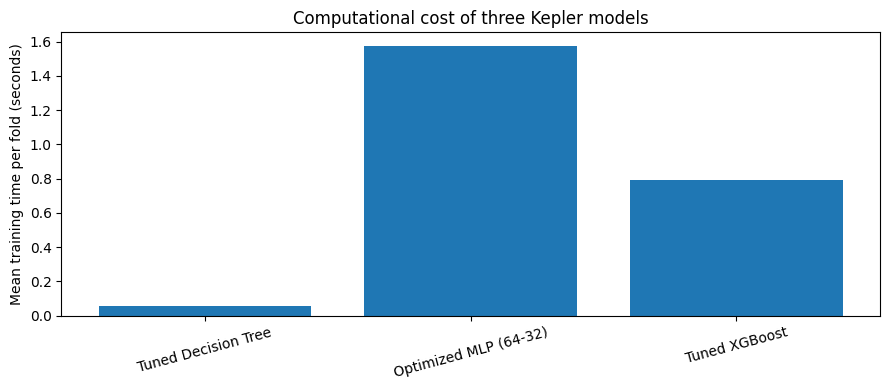

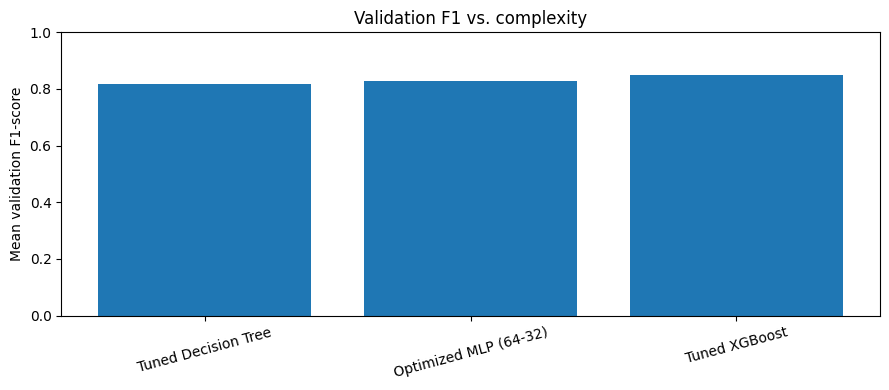

In [4]:
fig, ax = plt.subplots(figsize=(9,4))
ax.bar(comparison["model"],comparison["training_seconds"])
ax.set_ylabel("Mean training time per fold (seconds)")
ax.set_title("Computational cost of three Kepler models")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9,4))
ax.bar(comparison["model"],comparison["validation_f1"])
ax.set_ylim(0,1)
ax.set_ylabel("Mean validation F1-score")
ax.set_title("Validation F1 vs. complexity")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

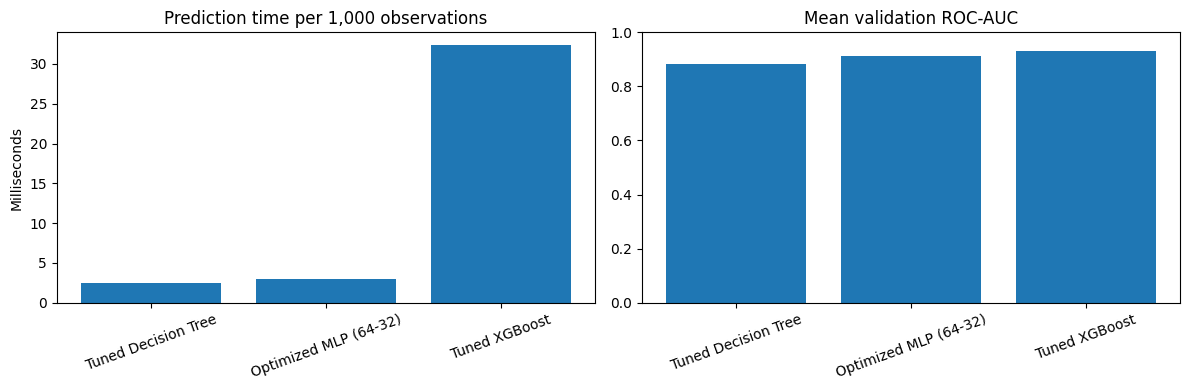

Structural complexity (not directly comparable units):


,model,mean_tree_nodes,mean_tree_leaves,mlp_parameters,boosting_trees
0,Tuned Decision Tree,204.2,102.6,NaN,NaN
1,Optimized MLP (64-32),NaN,NaN,3393.0,NaN
2,Tuned XGBoost,41570.0,21085.0,NaN,600.0


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(comparison["model"], comparison["prediction_ms_per_1000"])
axes[0].set_title("Prediction time per 1,000 observations")
axes[0].set_ylabel("Milliseconds")
axes[1].bar(comparison["model"], comparison["validation_roc_auc"])
axes[1].set_title("Mean validation ROC-AUC")
axes[1].set_ylim(0, 1)
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

print("Structural complexity (not directly comparable units):")
display(comparison[["model", "mean_tree_nodes", "mean_tree_leaves", "mlp_parameters", "boosting_trees"]].round(1))